# Overview: continued pretraining for PD

An entry point to the project's findings for probability of default (PD) classification. It synthesizes experiments 1, 2, 3, 5, 6, 7 and 8, plus experiment 4's context curves; experiment 0 (controls and pilots) is excluded. Every number is a paired difference between an adapted checkpoint and the original checkpoint of the same base, evaluated on the same held-out credit tables and outer folds within one study. Primary quantity: AUC change in percentage points (pp); positive always means CPT is better. The individual experiment notebooks hold the detailed evidence.

Sections in order: what was tested and how studies differ (1); how every configuration compares with its original model (2); how much that varies across tables (3); how learning rate and adaptation approach shape the effect (4); what adaptation costs on non-credit tables (5); whether CPT matters more when the target table supplies little labelled context (6); which tables move (7); training cost (8); and the strongest, weakest and most consistent configurations (9).

## 0. Evidence and scope

All comparisons use completed final five-fold benchmarks. A table enters a comparison only when the adapted and the original model both have five finite outer folds; missing results are excluded, never treated as zero.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, synthesis as sy, context_curves as cc
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('general/03_overview_pd')
report = cp.NotebookReport('Overview: continued pretraining for PD', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Paired within-study comparisons of every completed CPT configuration with its original model; experiment 0 is excluded.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Studies and what differs between them

Each study changes one named factor relative to its own control, but studies also differ in sampling, precision and episode settings. The comparability table makes those differences explicit before any cross-study figure is read.

In [2]:
studies = sy.load_studies(TRACK)
credit = sy.catalog(studies, sy.PRIMARY[TRACK])
retention = sy.catalog(studies, sy.PRIMARY[TRACK], domain='ood')
secondary = sy.catalog(studies, sy.SECONDARY[TRACK])
report.table('What differs between studies', sy.comparability_table(studies))
report.add('1. Studies and what differs between them', sy.STUDY_NOTE)

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,experiment,study,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,1,Main grid,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3","3e-07, 1e-06, 1e-05, 3e-05","0, 0.003",balanced,True,automatic,measured cap,42,256
1,2,Seed 43,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,balanced,True,automatic,measured cap,43,16
2,3,Sampling,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,stratified,True,automatic,measured cap,42,48
3,5,DiagScale,,"TabICLv2, TabPFN v3","0.0001, 0.001, 0.03",0,stratified,False,"FP32, no FA3",8192,42,24
4,6,Corpus policy,All tables,"TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,8192,42,8
5,6,Corpus policy,Large tables,"TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,8192,42,8
6,7,Episode size,"2,048 rows","TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,2048,42,8
7,7,Episode size,"26,000 rows","TabICLv2, TabPFN v3",3e-07,0.003,stratified,True,automatic,26000,42,8
8,8,LoRA,,"TabICLv2, TabPFN v3","1e-05, 0.0001, 0.001",0,balanced,True,"FP32, no FA3",measured cap,42,24


## 2. Every configuration against its original model

One row per configuration and one column per base: the equal-table mean paired change, followed by improved/total tables. Rows are grouped by experiment; label colour identifies the adaptation approach and the bold row is the predefined reference recipe.

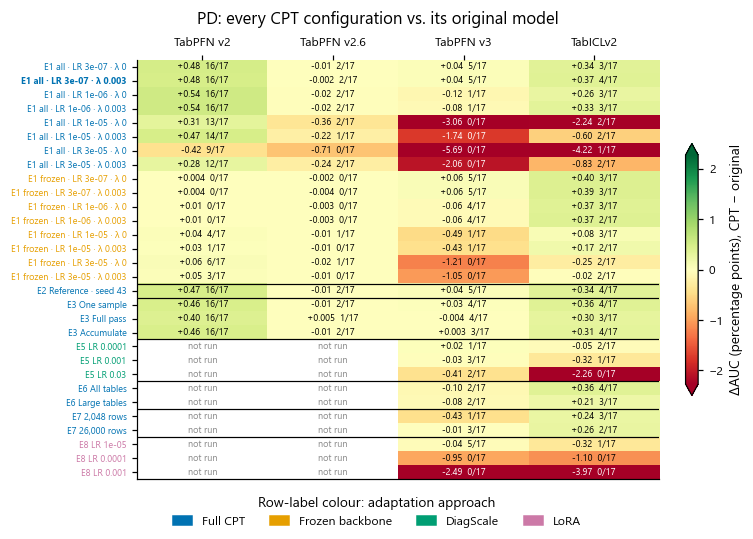

PD. Held-out credit tables, final five-fold benchmark. Each cell is the equal-table mean change in AUC (percentage points) of an adapted model relative to the original checkpoint of the same base, followed by the number of tables that improved by more than 0.1 pp and the number of complete tables. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Rows are grouped by experiment (E1 main grid: four learning rates × L2-SP λ ∈ {0, 0.003} × all or frozen-backbone updates; E2 the reference recipe with a second training seed; E3 sampling protocols; E5 DiagScale query-scaling adapters; E6 all versus large training tables; E7 episode sizes on the large-table corpus; E8 rank-16 query/value LoRA). The bold row is the predefined reference recipe (full updates, LR 3e-7, λ 0.003); every other row is reported in full rather than selected. Label colours identify the adaptation approach. Colours are symmetric about zero and saturate at the 95th percentile of |cell value| (2.27); printed values are exact. 'Not run' marks base/approach combinations outside a study's design. Studies differ in more than their named factor (see the comparability table).

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabICLv2,roc_auc,17,0.791790,0.792613,0.000823,...,-0.003289,0.000433,-0.035055,0.068600,3,4,10,26,85,0.176471
1,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2,roc_auc,17,0.778915,0.779312,0.000397,...,0.000011,0.000946,-0.002281,0.001725,4,12,1,55,85,0.235294
2,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2.6,roc_auc,17,0.792242,0.792135,-0.000107,...,-0.000282,-0.000042,-0.000702,0.001103,1,16,0,21,85,0.058824
3,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v3,roc_auc,17,0.798170,0.793301,-0.004868,...,-0.007981,-0.000676,-0.018535,0.002261,1,4,12,11,85,0.058824
4,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,17,0.791790,0.793514,0.001724,...,-0.002495,0.000567,-0.025888,0.069409,2,5,10,30,85,0.117647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E8 LR 0.0001,TabPFN v3,roc_auc,17,0.798177,0.788666,-0.009511,...,-0.010384,-0.002682,-0.040906,-0.001182,0,0,17,8,85,0.000000
96,8,LoRA,LoRA,E8 LR 0.001,TabICLv2,roc_auc,17,0.797067,0.757412,-0.039655,...,-0.047462,-0.020130,-0.158151,-0.001812,0,0,17,3,85,0.000000
97,8,LoRA,LoRA,E8 LR 0.001,TabPFN v3,roc_auc,17,0.798177,0.773259,-0.024917,...,-0.029129,-0.005759,-0.135683,-0.000960,0,1,16,2,85,0.000000
98,8,LoRA,LoRA,E8 LR 1e-05,TabICLv2,roc_auc,17,0.797067,0.793830,-0.003237,...,-0.002792,-0.000133,-0.025232,0.003325,1,7,9,17,85,0.058824


In [3]:
cp.show(sink, sy.plot_landscape(credit, TRACK), track=TRACK)
report.table('Every configuration: original and adapted scores, change and consistency', sy.summarize(credit))
report.add('2. Every configuration against its original model', sy.findings(credit, TRACK))

## 3. Variation across tables

Means can be carried by one or two tables. These figures use only configurations fixed independently of outcomes: experiment 1's predefined reference recipe, with all weights and with a frozen backbone, and every prescribed arm of the follow-up studies.

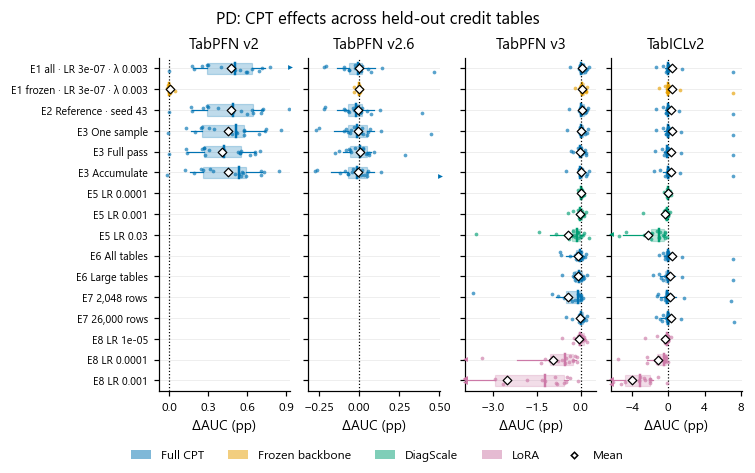

PD. Distribution over held-out credit tables of the paired change in AUC (percentage points) relative to each base's original model. Boxes span the table interquartile range, the thick line is the median, whiskers reach the 10th and 90th percentiles, dots are individual tables and the white diamond is the equal-table mean. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Experiment 1 contributes only its predefined reference recipe (LR 3e-7, L2-SP λ 0.003) with all parameters updated and with the backbone frozen; every follow-up contributes all prescribed arms, so no row is chosen by its outcome. Horizontal axes differ between models and span each model's 2nd-98th percentile of table effects and zero; tables outside that range are drawn as triangles at the axis edge (TabPFN v2: 1, TabPFN v2.6: 1, TabPFN v3: 5, TabICLv2: 3 tables) and keep their exact values in the summary. Spread describes heterogeneity across tables, not statistical uncertainty.

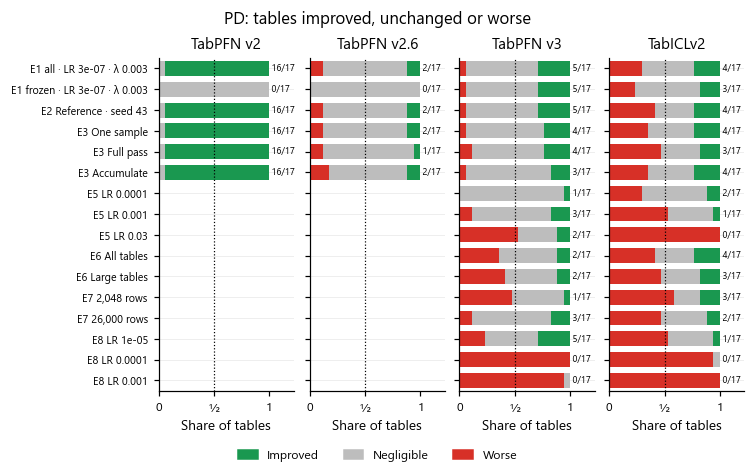

PD. For the same arms as the distribution figure, the share of held-out credit tables whose paired AUC change relative to the original model exceeds +0.1 percentage points (improved), lies within ±0.1 (negligible) or falls below −0.1 (worse); numbers give improved/total tables. The ±0.1 band is a reporting convention for this study, not a statistical equivalence margin. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The dotted line marks half of the tables.

In [4]:
cp.show(sink, sy.plot_distributions(credit, TRACK), track=TRACK)
cp.show(sink, sy.plot_outcomes(credit, TRACK), track=TRACK)
report.add('3. Variation across tables', 'Improved, negligible and worse use a band of ' + str(sy.style.TIE_BAND[sy.PRIMARY[TRACK]]) + ' on the native metric scale. Spread describes heterogeneity across tables, not statistical uncertainty.')

## 4. Learning rate and adaptation approach

How each approach responds to its peak learning rate. Full and frozen-backbone CPT come from experiment 1, DiagScale from experiment 5 and LoRA from experiment 8.

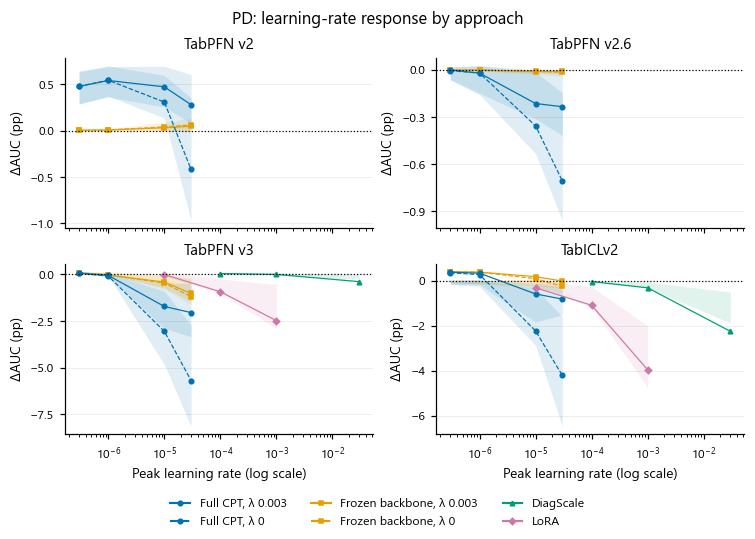

PD. Equal-table mean paired change in AUC (percentage points) relative to the original model, against peak learning rate, for full-parameter and frozen-backbone CPT (experiment 1; solid λ = 0.003, dashed λ = 0), DiagScale query-scaling adapters (experiment 5) and query/value LoRA (experiment 8). Shaded bands span the table interquartile range, not confidence intervals. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The rate scales are not interchangeable across approaches: DiagScale updates multiplicative query scales and LoRA updates low-rank factors, so their rates are shown on a common axis only to display each approach's own sensitivity. The studies also differ in PD sampling, training precision and TabICLv2 inference settings.

In [5]:
cp.show(sink, sy.plot_rate_response(credit, TRACK), track=TRACK)
report.add('4. Learning rate and adaptation approach', 'Learning-rate scales differ in meaning between approaches; compare the shape of each curve rather than rates across approaches.')

## 5. Credit transfer against non-credit retention

Gains on held-out credit tables matter only if the model keeps working elsewhere. Each configuration's credit change is placed against its change on the four same-task non-credit tables.

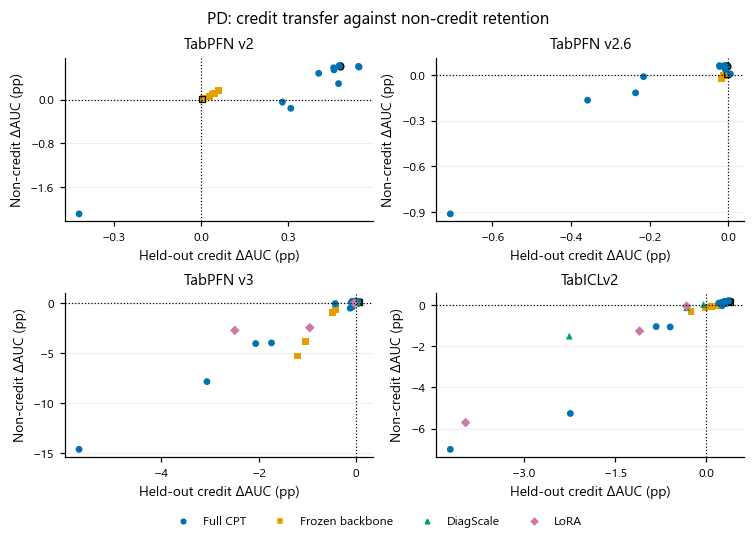

PD. Each point is one configuration: its equal-table mean paired change on held-out credit tables (horizontal) and on the four non-credit retention tables of the same task (vertical), both relative to the original model of the same base. Non-credit tables first average all four CPT training partitions. The upper-right quadrant improves both; the lower-right gains on credit while losing on the retention panel. Points outlined in black are the experiment-1 reference recipes (full and frozen). Axis limits differ between models. A four-table retention panel does not establish general retention. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabICLv2,roc_auc,4,0.872510,0.871842,-0.000668,...,-0.003839,0.002106,-0.009615,0.009073,1,1,2,25,80,0.25
1,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2,roc_auc,4,0.848628,0.849670,0.001042,...,0.000391,0.001624,0.000056,0.002168,2,2,0,62,80,0.50
2,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2.6,roc_auc,4,0.871975,0.871927,-0.000048,...,-0.000178,0.000206,-0.000586,0.000241,0,4,0,34,80,0.00
3,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v3,roc_auc,4,0.872980,0.863178,-0.009802,...,-0.011333,-0.002036,-0.031337,-0.000736,0,1,3,14,80,0.00
4,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,4,0.872510,0.871955,-0.000555,...,-0.003586,0.002047,-0.009040,0.008790,1,1,2,27,80,0.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E8 LR 0.0001,TabPFN v3,roc_auc,4,0.872980,0.848413,-0.024566,...,-0.037825,-0.002209,-0.066927,-0.000405,0,1,3,10,80,0.00
96,8,LoRA,LoRA,E8 LR 0.001,TabICLv2,roc_auc,4,0.874683,0.817568,-0.057115,...,-0.078950,-0.016556,-0.143197,-0.008479,0,0,4,5,80,0.00
97,8,LoRA,LoRA,E8 LR 0.001,TabPFN v3,roc_auc,4,0.872980,0.845662,-0.027318,...,-0.031722,-0.019818,-0.053757,-0.007070,0,0,4,2,80,0.00
98,8,LoRA,LoRA,E8 LR 1e-05,TabICLv2,roc_auc,4,0.874683,0.874051,-0.000631,...,-0.001898,0.000797,-0.003190,0.001603,1,1,2,34,80,0.25


In [6]:
cp.show(sink, sy.plot_transfer_retention(credit, retention, TRACK), track=TRACK)
report.table('Non-credit retention per configuration', sy.summarize(retention))
report.add('5. Credit transfer against non-credit retention', 'Non-credit tables average all four CPT partitions. The retention panel contains four tables per task.')

## 6. Labelled context at prediction time (experiment 4)

The reference CPT checkpoints of TabPFN v3 and TabICLv2 are evaluated with nested labelled contexts from 8 rows up to 50,000, on identical test rows.

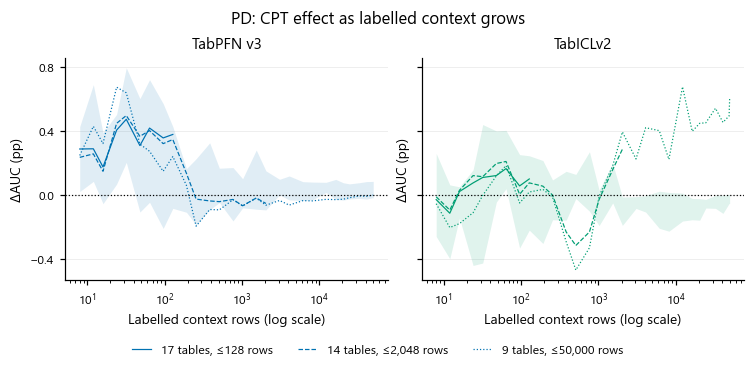

PD. Experiment 4: paired change in AUC (percentage points) of the fixed reference CPT checkpoint (experiment 1: full updates, LR 3e-7, L2-SP λ 0.003) relative to its original model, as a function of the number of labelled context rows supplied at prediction time. Contexts are nested prefixes and test rows are identical for both weight states. Each line is a fixed table cohort that contributes at every size up to its horizon; the band spans the table interquartile range for the longest-horizon cohort. Five outer folds are averaged within table before tables are weighted equally. The curves do not estimate variation over independently resampled contexts.

In [7]:
study = cc.load_context_study()
cp.show(sink, sy.plot_context_gain(study, TRACK), track=TRACK)
report.add('6. Labelled context at prediction time (experiment 4)', 'Each cohort contains the tables that support every context size up to its horizon; validation labels are a fixed additional budget.')

## 7. Which tables move?

Table-by-arm maps for each base, rows ordered by the original model's score, and the reference recipe's effect against the original score.

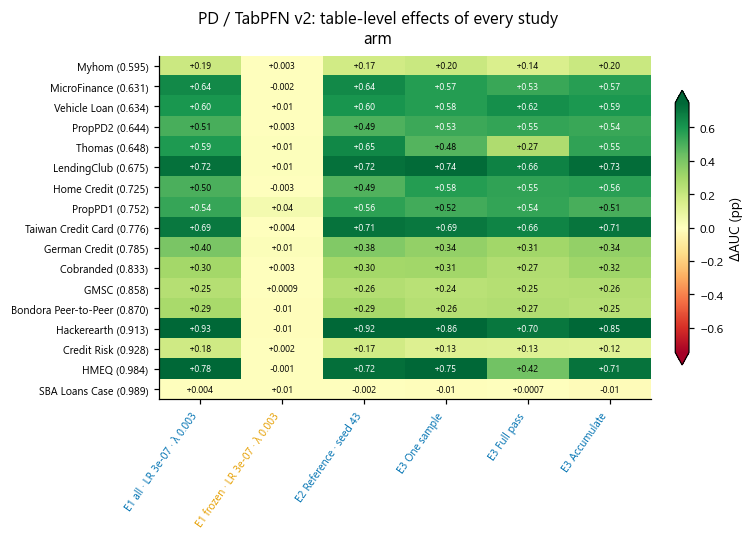

PD. TabPFN v2, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model. Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the arms' identical original evaluations); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Colours are symmetric about zero and saturate at the 95th percentile of |value| (0.75); printed values are exact. '—' marks a missing complete comparison.

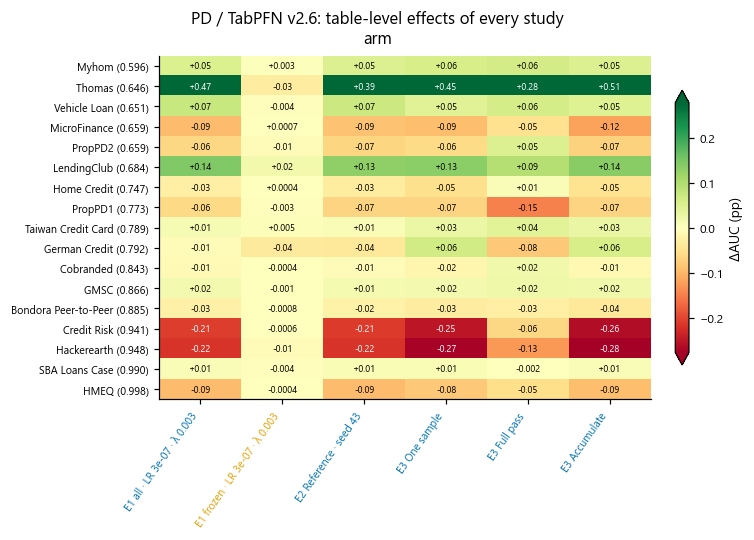

PD. TabPFN v2.6, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model. Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the arms' identical original evaluations); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Colours are symmetric about zero and saturate at the 95th percentile of |value| (0.28); printed values are exact. '—' marks a missing complete comparison.

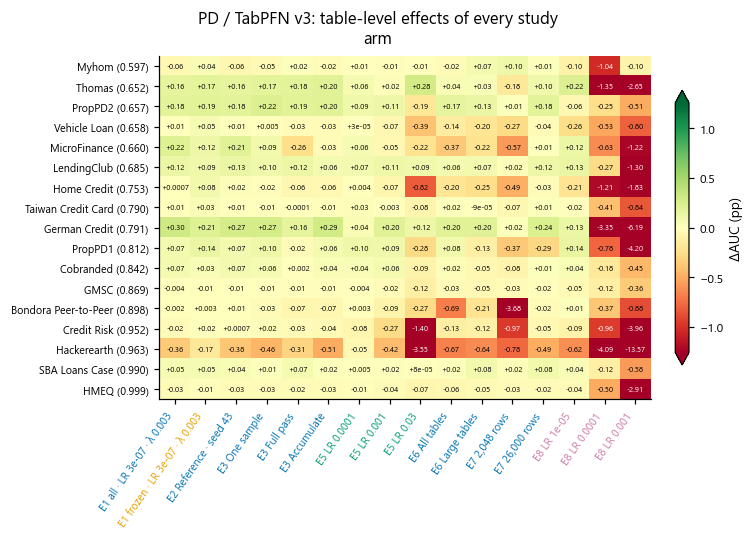

PD. TabPFN v3, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model. Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the arms' identical original evaluations); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Colours are symmetric about zero and saturate at the 95th percentile of |value| (1.26); printed values are exact. '—' marks a missing complete comparison.

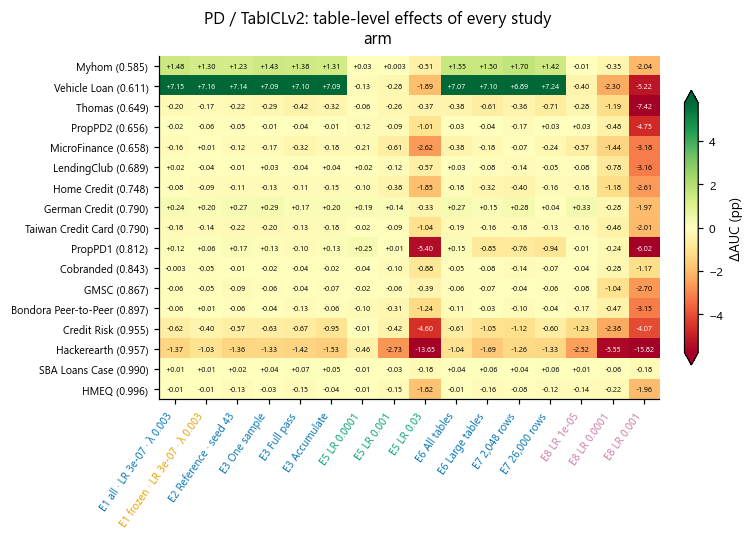

PD. TabICLv2, held-out credit tables: paired change in AUC (percentage points) of each study arm relative to the original model. Rows are tables, ordered by the original model's mean score (in parentheses, averaged over the arms' identical original evaluations); columns are the outcome-independent arms of the distribution figure, coloured by approach. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Colours are symmetric about zero and saturate at the 95th percentile of |value| (5.76); printed values are exact. '—' marks a missing complete comparison.

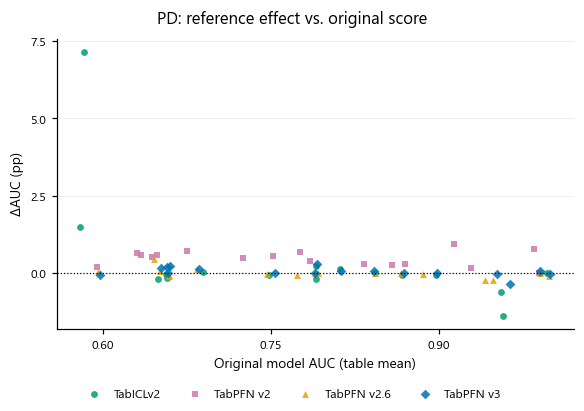

PD. Predefined reference recipe (experiment 1: full updates, LR 3e-7, L2-SP λ 0.003): each point is one held-out credit table and base, plotting the paired change in AUC (percentage points) against the original model's mean score on that table. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. The horizontal score appears in both quantities (the change is computed from it), so a trend can arise from ceiling effects or noise and is descriptive, not a mechanism.

In [8]:
for base in sy.BASES:
    cp.show(sink, sy.plot_table_map(credit, TRACK, base), track=TRACK)
cp.show(sink, sy.plot_headroom(credit, TRACK), track=TRACK)
report.add('7. Which tables move?', 'Table identities persist across arms within a base. The original score also enters the change, so trends against it are descriptive.')

## 8. Training cost

Recorded training time summed over the four CPT partitions, against the mean change.

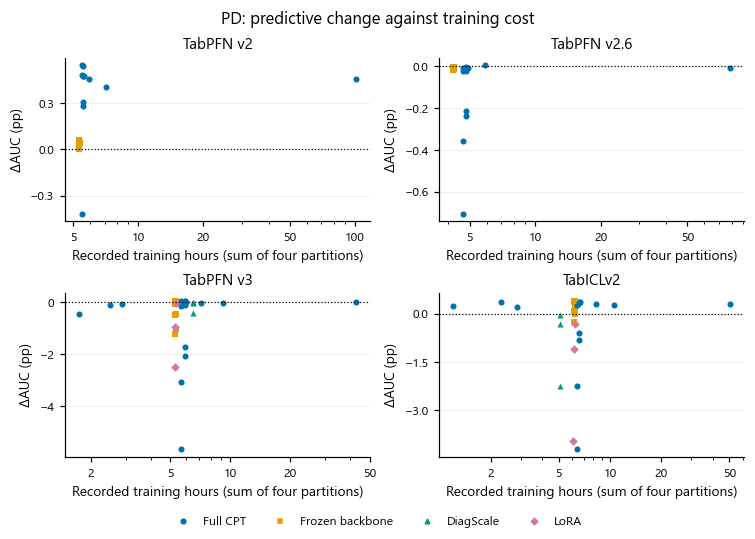

PD. Each point is one configuration: its equal-table mean paired change in AUC (percentage points) on held-out credit tables against recorded training time summed over the four CPT partitions (logarithmic axis). Training time excludes evaluation and queueing and was recorded on the GPUs used for each study, so it is an observed cost, not a matched-compute comparison. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

In [9]:
cp.show(sink, sy.plot_cost_effect(credit, sy.costs(studies), TRACK), track=TRACK)
report.add('8. Training cost', 'Recorded training time excludes evaluation and queueing and was measured on the hardware of each study; it is not a matched-compute comparison.')

## 9. Strongest, weakest and most consistent configurations

Observed extremes over many configurations are optimistic. The selection table therefore also reports a leave-one-table-out choice within experiment 1: the recipe with the best mean on the other tables, scored on the held-out table.

In [10]:
report.table('Highest, lowest and most consistent configuration per base', sy.extremes(sy.summarize(credit)))
report.table('Experiment 1: predefined reference, observed best and leave-one-table-out selection', sy.selection_check(credit[credit.experiment.eq(1)]))
report.table('Secondary metric (Brier-score reduction) per configuration', sy.summarize(secondary))
report.add('9. Strongest, weakest and most consistent configurations', 'Most consistent means the largest share of tables improved beyond the negligible band, ties broken by the median. Highest and lowest means are observed extremes, not validated recipes.')

,base,role,configuration,mean,median,improved,negligible,worse,tables
0,TabICLv2,Highest observed mean,E1 frozen · LR 3e-07 · λ 0,0.003964,-0.000345,3,10,4,17
1,TabICLv2,Lowest observed mean,E1 all · LR 3e-05 · λ 0,-0.042181,-0.037627,1,0,16,17
2,TabICLv2,Most tables improved,E1 all · LR 3e-07 · λ 0.003,0.003695,-0.000176,4,8,5,17
3,TabPFN v2,Highest observed mean,E1 all · LR 1e-06 · λ 0,0.005437,0.005413,16,1,0,17
4,TabPFN v2,Lowest observed mean,E1 all · LR 3e-05 · λ 0,-0.004190,0.001455,9,3,5,17
5,TabPFN v2,Most tables improved,E1 all · LR 1e-06 · λ 0,0.005437,0.005413,16,1,0,17
6,TabPFN v2.6,Highest observed mean,E3 Full pass,0.000049,0.000073,1,14,2,17
7,TabPFN v2.6,Lowest observed mean,E1 all · LR 3e-05 · λ 0,-0.007067,-0.004303,0,2,15,17
8,TabPFN v2.6,Most tables improved,E1 all · LR 1e-06 · λ 0.003,-0.000225,-0.000079,2,9,6,17
9,TabPFN v3,Highest observed mean,E1 frozen · LR 3e-07 · λ 0.003,0.000603,0.000495,5,11,1,17


,base,tables,recipes,reference_recipe,reference_mean,best_observed_recipe,best_observed_mean,leave_one_table_out_mean,leave_one_table_out_improved,recipes_chosen
0,TabICLv2,17,16,E1 all · LR 3e-07 · λ 0.003,0.003695,E1 frozen · LR 3e-07 · λ 0,0.003964,0.003552,5,"E1 frozen · LR 3e-07 · λ 0 ×15, E1 frozen · LR..."
1,TabPFN v2,17,16,E1 all · LR 3e-07 · λ 0.003,0.004773,E1 all · LR 1e-06 · λ 0,0.005437,0.005437,17,E1 all · LR 1e-06 · λ 0 ×17
2,TabPFN v2.6,17,16,E1 all · LR 3e-07 · λ 0.003,-0.000024,E1 frozen · LR 3e-07 · λ 0,-0.000016,-0.000488,2,"E1 all · LR 3e-07 · λ 0.003 ×8, E1 frozen · LR..."
3,TabPFN v3,17,16,E1 all · LR 3e-07 · λ 0.003,0.000430,E1 frozen · LR 3e-07 · λ 0.003,0.000603,0.000603,14,E1 frozen · LR 3e-07 · λ 0.003 ×17


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabICLv2,brier_score,17,0.120268,0.115047,0.005221,...,-0.001339,-0.000018,-0.023862,0.112567,3,2,12,24,85,0.176471
1,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2,brier_score,17,0.118123,0.118112,0.000011,...,-0.000159,0.000187,-0.001249,0.001395,7,3,7,35,85,0.411765
2,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2.6,brier_score,17,0.113695,0.113737,-0.000042,...,-0.000069,0.000044,-0.000441,0.000193,2,11,4,36,85,0.117647
3,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v3,brier_score,17,0.111856,0.114078,-0.002222,...,-0.002976,-0.000342,-0.015627,0.000338,1,2,14,12,85,0.058824
4,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0.003,TabICLv2,brier_score,17,0.120268,0.114478,0.005790,...,-0.000526,0.000134,-0.018990,0.112654,5,0,12,27,85,0.294118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,LoRA,LoRA,E8 LR 0.0001,TabPFN v3,brier_score,17,0.111856,0.116905,-0.005049,...,-0.004431,-0.000604,-0.030415,0.000085,0,1,16,9,85,0.000000
96,8,LoRA,LoRA,E8 LR 0.001,TabICLv2,brier_score,17,0.112620,0.126934,-0.014314,...,-0.018515,-0.004757,-0.073268,-0.001342,0,0,17,1,85,0.000000
97,8,LoRA,LoRA,E8 LR 0.001,TabPFN v3,brier_score,17,0.111856,0.123470,-0.011614,...,-0.009543,-0.001137,-0.069155,-0.000215,0,0,17,1,85,0.000000
98,8,LoRA,LoRA,E8 LR 1e-05,TabICLv2,brier_score,17,0.112620,0.114662,-0.002042,...,-0.000626,-0.000072,-0.019691,0.000238,1,4,12,14,85,0.058824


## Complete text summary

Every displayed value, table and caption, in section order.

In [11]:
print(report.summary(sink))

Overview: continued pretraining for PD

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Paired within-study comparisons of every completed CPT configuration with its original model; experiment 0 is excluded.

1. Studies and what differs between them
Experiment 0 (controls and pilots) is excluded. Each study pairs its adapted checkpoints with its own evaluation of the original model, under that study's inference settings, so every effect in this notebook is a within-study paired difference. Experiments 1–3 use TabPFN v2, TabPFN v2.6, TabPFN v3 and TabICLv2; experiments 5–8 use TabPFN v3 and TabICLv2. Experiment 4 reuses the experiment-1 reference checkpoints at varying context sizes. Experiments 6 and 7 are PD-only. Cross-study contrasts can involve several recipe differences at once (see the comparability table: PD sampling, training precision, TabICLv2 